In [ ]:
# ---- Cell 1: imports, seed, versions ----
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, classification_report,
                             roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

print("Python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("scipy       :", scipy.__version__)

Python      : 3.13.18
numpy       : 2.4.6
pandas      : 2.2.3
scikit-learn: 1.6.1
scipy       : 1.16.3


Role: Data scientist for a community health-screening programme.
Question: Can routine measurements (glucose, BMI, age, ...) flag people who should be sent
for a confirmatory diabetes test?
Positive class (1): the person has diabetes. Negative class (0): the person does not.
Who acts: Nurses/clinicians, who refer flagged people for a full lab test.
Cost of errors:
  - False negative (FN) = a person with diabetes is told "low risk" -> untreated disease (serious).
  - False positive (FP) = a healthy person is referred for an extra test -> cost, worry (less serious).
Primary metric: Recall (sensitivity) at an acceptable precision; also ROC-AUC and F1.
Baseline: always predict "no diabetes" (majority class).

In [ ]:
# ---- Cell 2: load ----
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
df = pd.read_csv(URL, header=None, names=cols)

print("Rows, columns:", df.shape)
df.head(10)

Rows, columns: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [ ]:
# ---- Cell 3: data types, summary, quality checks ----
print(df.dtypes, "\n")
display(df.describe().T)
print("\nMissing values (NaN):\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Unique label values:", sorted(df["Outcome"].unique()))   # should be [0, 1] only

# Impossible zeros: a person cannot have 0 glucose, 0 blood pressure, 0 BMI, etc.
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("\nZero values per column (physiologically impossible):")
print((df[zero_cols] == 0).sum())

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object 



,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00



Missing values (NaN):
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0
Unique label values: [np.int64(0), np.int64(1)]

Zero values per column (physiologically impossible):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [ ]:
# ---- Cell 4: convert impossible zeros to NaN ----
df[zero_cols] = df[zero_cols].replace(0, np.nan)
print(df[zero_cols].isna().sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


         Count  Percent
Outcome                
0          500     65.1
1          268     34.9


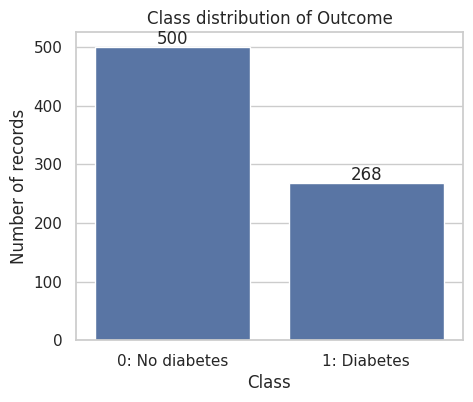

In [ ]:
# ---- Cell 5: class distribution bar chart ----
counts = df["Outcome"].value_counts().sort_index()
pct = df["Outcome"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"Count": counts, "Percent": pct.round(1)}))

plt.figure(figsize=(5, 4))
ax = sns.barplot(x=["0: No diabetes", "1: Diabetes"], y=counts.values)
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha="center")
plt.title("Class distribution of Outcome")
plt.xlabel("Class")
plt.ylabel("Number of records")
plt.show()

In [ ]:
# ---- Cell 6: X, y, stratified 80:20 split ----
FEATURES = cols[:-1]
X = df[FEATURES]
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print("Training observations:", len(X_train), "| Testing observations:", len(X_test))
print("\nTrain class counts:\n", y_train.value_counts().sort_index())
print("\nTest class counts:\n", y_test.value_counts().sort_index())
print("\nTrain positive share: %.3f | Test positive share: %.3f" % (y_train.mean(), y_test.mean()))

Training observations: 614 | Testing observations: 154

Train class counts:
 Outcome
0    400
1    214
Name: count, dtype: int64

Test class counts:
 Outcome
0    100
1     54
Name: count, dtype: int64

Train positive share: 0.349 | Test positive share: 0.351


In [ ]:
# ---- Cell 7: preprocessing + model in ONE pipeline (imputer and scaler are fit on train only) ----
model = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
    ("clf",    LogisticRegression(max_iter=1000, random_state=SEED))
])

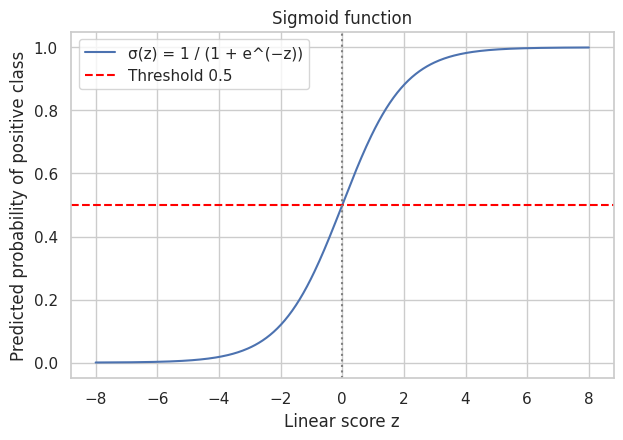

In [ ]:
# ---- Cell 8: sigmoid plot ----
z = np.linspace(-8, 8, 400)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(7, 4.5))
plt.plot(z, sigmoid, label="σ(z) = 1 / (1 + e^(−z))")
plt.axhline(0.5, color="red", linestyle="--", label="Threshold 0.5")
plt.axvline(0, color="gray", linestyle=":")
plt.title("Sigmoid function")
plt.xlabel("Linear score z")
plt.ylabel("Predicted probability of positive class")
plt.legend()
plt.show()

In [ ]:
# ---- Cell 9: train on TRAIN only ----
model.fit(X_train, y_train)

clf = model.named_steps["clf"]
print("Model settings:", clf.get_params())
print(f"\nIntercept: {clf.intercept_[0]:.4f}")

coef_df = pd.DataFrame({
    "Feature": FEATURES,
    "Coefficient (per 1 SD)": clf.coef_[0],
    "Odds ratio (e^coef)": np.exp(clf.coef_[0])
}).sort_values("Coefficient (per 1 SD)", key=abs, ascending=False)
display(coef_df.round(4))

Model settings: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Intercept: -0.8722


,Feature,Coefficient (per 1 SD),Odds ratio (e^coef)
1,Glucose,1.1826,3.2627
5,BMI,0.6887,1.9910
0,Pregnancies,0.3774,1.4586
6,DiabetesPedigreeFunction,0.2333,1.2628
7,Age,0.1478,1.1593
4,Insulin,-0.0661,0.9360
2,BloodPressure,-0.0441,0.9568
3,SkinThickness,0.0283,1.0287


In [ ]:
# ---- Cell 10: probabilities and labels on the TEST set ----
proba_test = model.predict_proba(X_test)[:, 1]     # probability of class 1
pred_test  = (proba_test >= 0.5).astype(int)       # default 0.5 threshold

sample_view = pd.DataFrame({
    "Actual label": y_test.values,
    "Predicted probability": proba_test.round(3),
    "Predicted label (0.5)": pred_test
}, index=y_test.index)
display(sample_view.head(15))

,Actual label,Predicted probability,Predicted label (0.5)
44,0,0.610,1
672,0,0.118,0
700,0,0.293,0
630,1,0.251,0
81,0,0.034,0
389,0,0.168,0
387,1,0.488,0
408,1,0.924,1
163,0,0.081,0
335,0,0.839,1


In [ ]:
# ---- Cell 11: effect of threshold on the number predicted positive ----
for t in [0.3, 0.5, 0.7]:
    n_pos = int((proba_test >= t).sum())
    print(f"Threshold {t}: {n_pos} of {len(proba_test)} test records predicted positive "
          f"({100*n_pos/len(proba_test):.1f}%)")
print("Actual positives in test set:", int(y_test.sum()))

Threshold 0.3: 72 of 154 test records predicted positive (46.8%)
Threshold 0.5: 45 of 154 test records predicted positive (29.2%)
Threshold 0.7: 28 of 154 test records predicted positive (18.2%)
Actual positives in test set: 54


TN = 82, FP = 18, FN = 27, TP = 27


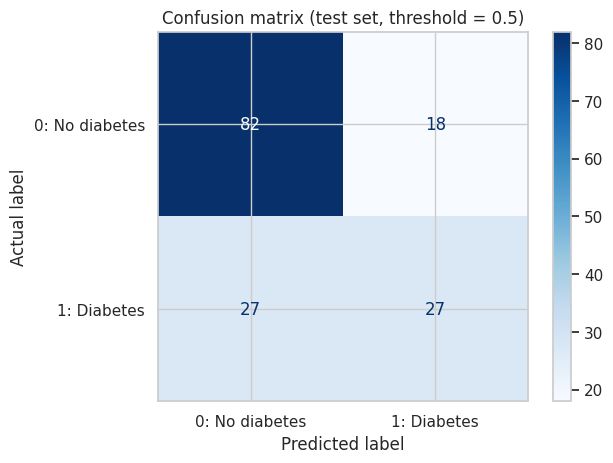

In [ ]:
# ---- Cell 12: confusion matrix (threshold 0.5) ----
cm = confusion_matrix(y_test, pred_test)
tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

disp = ConfusionMatrixDisplay(cm, display_labels=["0: No diabetes", "1: Diabetes"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix (test set, threshold = 0.5)")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.show()

In [ ]:
# ---- Cell 13: metrics from the confusion matrix (formulas written out) ----
accuracy    = (tp + tn) / (tp + tn + fp + fn)
precision   = tp / (tp + fp) if (tp + fp) else 0
recall      = tp / (tp + fn)
specificity = tn / (tn + fp)
f1          = 2 * precision * recall / (precision + recall) if (precision + recall) else 0
auc         = roc_auc_score(y_test, proba_test)

# Cross-check with sklearn
assert np.isclose(accuracy, accuracy_score(y_test, pred_test))
assert np.isclose(precision, precision_score(y_test, pred_test))
assert np.isclose(recall, recall_score(y_test, pred_test))
assert np.isclose(f1, f1_score(y_test, pred_test))

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall (sensitivity)", "Specificity", "F1-score", "ROC-AUC"],
    "Formula": ["(TP+TN)/(TP+TN+FP+FN)", "TP/(TP+FP)", "TP/(TP+FN)", "TN/(TN+FP)",
                "2*P*R/(P+R)", "Area under ROC curve"],
    "Your test-set result": [accuracy, precision, recall, specificity, f1, auc]
})
display(results.round(3))

,Metric,Formula,Your test-set result
0,Accuracy,(TP+TN)/(TP+TN+FP+FN),0.708
1,Precision,TP/(TP+FP),0.600
2,Recall (sensitivity),TP/(TP+FN),0.500
3,Specificity,TN/(TN+FP),0.820
4,F1-score,2*P*R/(P+R),0.545
5,ROC-AUC,Area under ROC curve,0.813


In [ ]:
# ---- Cell 14: full classification report ----
print(classification_report(y_test, pred_test, target_names=["0: No diabetes", "1: Diabetes"]))

                precision    recall  f1-score   support

0: No diabetes       0.75      0.82      0.78       100
   1: Diabetes       0.60      0.50      0.55        54

      accuracy                           0.71       154
     macro avg       0.68      0.66      0.67       154
  weighted avg       0.70      0.71      0.70       154



In [ ]:
# ---- Cell 15: baseline that always predicts the majority class ----
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
base_pred = base.predict(X_test)

print("Baseline accuracy :", round(accuracy_score(y_test, base_pred), 3))
print("Baseline recall   :", round(recall_score(y_test, base_pred), 3))
print("Baseline precision:", round(precision_score(y_test, base_pred, zero_division=0), 3))
print("Baseline F1       :", round(f1_score(y_test, base_pred, zero_division=0), 3))
print("Baseline ROC-AUC  :", round(roc_auc_score(y_test, base.predict_proba(X_test)[:, 1]), 3))
print("\nLogistic Regression accuracy:", round(accuracy, 3), "| recall:", round(recall, 3))

Baseline accuracy : 0.649
Baseline recall   : 0.0
Baseline precision: 0.0
Baseline F1       : 0.0
Baseline ROC-AUC  : 0.5

Logistic Regression accuracy: 0.708 | recall: 0.5


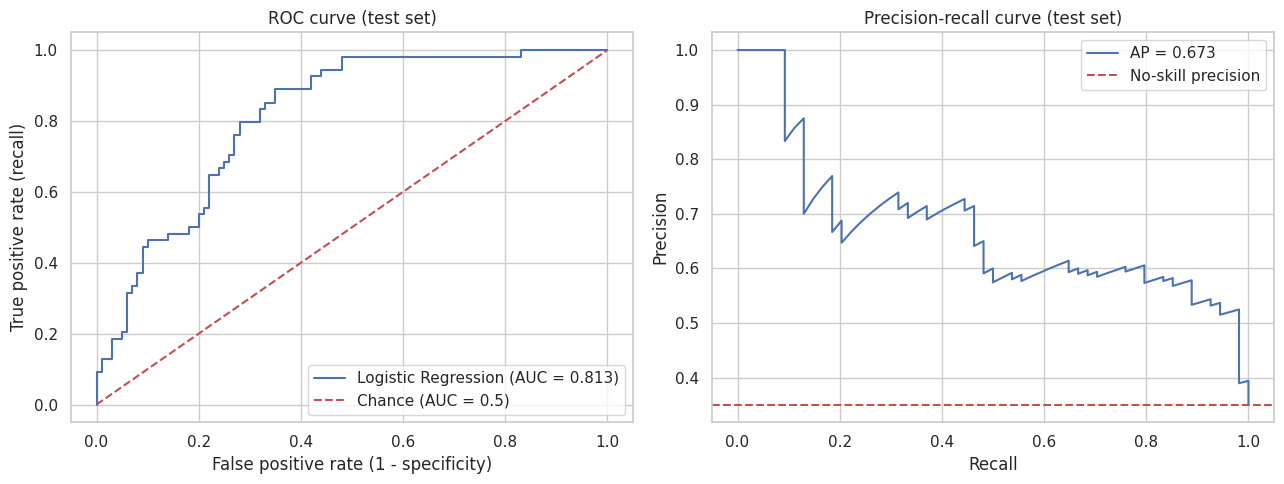

In [ ]:
# ---- Cell 16: ROC and PR curves ----
fpr, tpr, roc_thr = roc_curve(y_test, proba_test)
prec_c, rec_c, pr_thr = precision_recall_curve(y_test, proba_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
axes[0].plot([0, 1], [0, 1], "r--", label="Chance (AUC = 0.5)")
axes[0].set_title("ROC curve (test set)")
axes[0].set_xlabel("False positive rate (1 - specificity)")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].legend()

axes[1].plot(rec_c, prec_c, label=f"AP = {average_precision_score(y_test, proba_test):.3f}")
axes[1].axhline(y_test.mean(), color="r", linestyle="--", label="No-skill precision")
axes[1].set_title("Precision-recall curve (test set)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# ---- Cell 17: metrics at thresholds 0.3, 0.5, 0.7 (TEST set) ----
rows = []
for t in [0.3, 0.5, 0.7]:
    p = (proba_test >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Predicted positive": int(p.sum()),
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p, zero_division=0),
        "Recall": recall_score(y_test, p),
        "F1-score": f1_score(y_test, p, zero_division=0),
        "FN (missed)": int(((p == 0) & (y_test.values == 1)).sum()),
        "FP (false alarms)": int(((p == 1) & (y_test.values == 0)).sum()),
    })
thr_table = pd.DataFrame(rows).set_index("Threshold")
display(thr_table.round(3))

,Predicted positive,Accuracy,Precision,Recall,F1-score,FN (missed),FP (false alarms)
Threshold,,,,,,,
0.3,72,0.740,0.597,0.796,0.683,11,29
0.5,45,0.708,0.600,0.500,0.545,27,18
0.7,28,0.727,0.714,0.370,0.488,34,8


In [ ]:
# ---- Cell 18: pick a threshold on TRAIN data using cross-validation ----
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_proba = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

TARGET_RECALL = 0.80     # clinical goal: catch at least 80% of diabetic people
cands = np.arange(0.10, 0.91, 0.01)
table = []
for t in cands:
    p = (cv_proba >= t).astype(int)
    table.append((t, recall_score(y_train, p), precision_score(y_train, p, zero_division=0)))
table = pd.DataFrame(table, columns=["threshold", "recall", "precision"])

ok = table[table["recall"] >= TARGET_RECALL]
chosen_t = ok["threshold"].max()          # highest threshold that still meets the recall goal
print("Recommended threshold (from training CV):", round(chosen_t, 2))
display(table[np.isclose(table["threshold"], chosen_t)].round(3))

# Now report it ONCE on the test set
p_final = (proba_test >= chosen_t).astype(int)
cm_f = confusion_matrix(y_test, p_final)
print("\nTest-set confusion matrix at the recommended threshold:\n", cm_f)
print("Accuracy :", round(accuracy_score(y_test, p_final), 3))
print("Precision:", round(precision_score(y_test, p_final), 3))
print("Recall   :", round(recall_score(y_test, p_final), 3))
print("F1       :", round(f1_score(y_test, p_final), 3))

Recommended threshold (from training CV): 0.28


,threshold,recall,precision
18,0.28,0.804,0.581



Test-set confusion matrix at the recommended threshold:
 [[67 33]
 [ 9 45]]
Accuracy : 0.727
Precision: 0.577
Recall   : 0.833
F1       : 0.682


In [ ]:
# ---- Cell 19: train vs test comparison ----
proba_train = model.predict_proba(X_train)[:, 1]
pred_train = (proba_train >= 0.5).astype(int)

compare = pd.DataFrame({
    "Train": [accuracy_score(y_train, pred_train), precision_score(y_train, pred_train),
              recall_score(y_train, pred_train), f1_score(y_train, pred_train),
              roc_auc_score(y_train, proba_train)],
    "Test":  [accuracy, precision, recall, f1, auc]
}, index=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])
display(compare.round(3))

,Train,Test
Accuracy,0.796,0.708
Precision,0.770,0.600
Recall,0.593,0.500
F1,0.670,0.545
ROC-AUC,0.850,0.813


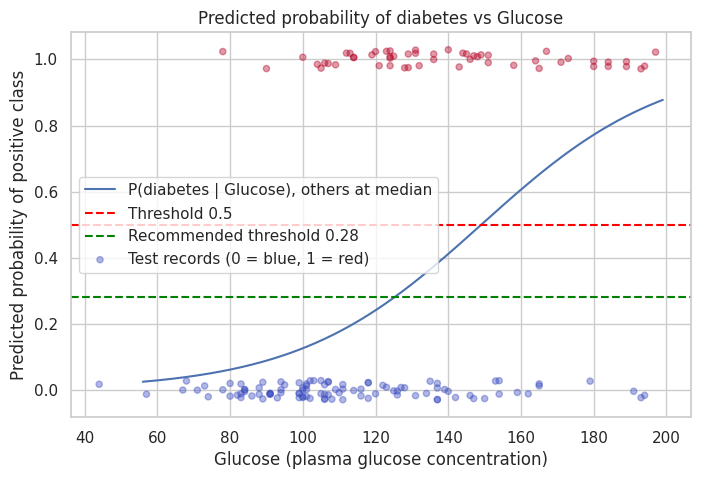

In [ ]:
# ---- Cell 20: predicted probability vs Glucose, other features held at their medians ----
grid = pd.DataFrame({f: X_train[f].median() for f in FEATURES}, index=range(200))
grid["Glucose"] = np.linspace(X_train["Glucose"].min(), X_train["Glucose"].max(), 200)
grid_proba = model.predict_proba(grid)[:, 1]

plt.figure(figsize=(8, 5))
plt.plot(grid["Glucose"], grid_proba, label="P(diabetes | Glucose), others at median")
plt.axhline(0.5, color="red", linestyle="--", label="Threshold 0.5")
plt.axhline(chosen_t, color="green", linestyle="--", label=f"Recommended threshold {chosen_t:.2f}")

# Real test points (actual labels) along the bottom/top
jitter = np.random.uniform(-0.03, 0.03, len(X_test))
plt.scatter(X_test["Glucose"], y_test + jitter, c=y_test, cmap="coolwarm", alpha=0.4, s=20,
            label="Test records (0 = blue, 1 = red)")
plt.title("Predicted probability of diabetes vs Glucose")
plt.xlabel("Glucose (plasma glucose concentration)")
plt.ylabel("Predicted probability of positive class")
plt.legend()
plt.show()

In [ ]:
# ---- Cell 21: one new record, same preprocessing via the pipeline ----
new_person = pd.DataFrame([{
    "Pregnancies": 2, "Glucose": 150, "BloodPressure": 80, "SkinThickness": 30,
    "Insulin": 120, "BMI": 33.0, "DiabetesPedigreeFunction": 0.5, "Age": 45
}])[FEATURES]

# Check the values are inside the training range
for f in FEATURES:
    lo, hi = X_train[f].min(), X_train[f].max()
    if not (lo <= new_person.loc[0, f] <= hi):
        print(f"WARNING: {f} outside training range [{lo}, {hi}]")

p_new = model.predict_proba(new_person)[0, 1]
print(f"Predicted probability of diabetes: {p_new:.3f}")
print(f"Class at 0.5 threshold          : {int(p_new >= 0.5)}")
print(f"Class at recommended {chosen_t:.2f}     : {int(p_new >= chosen_t)}")

Predicted probability of diabetes: 0.561
Class at 0.5 threshold          : 1
Class at recommended 0.28     : 1
